In [1]:
%pip install -U langchain-community

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -U arxiv wikipedia

  Using cached arxiv-4.0.2-py3-none-any.whl.metadata (5.9 kB)
Using cached arxiv-4.0.2-py3-none-any.whl (13 kB)
  Attempting uninstall: arxiv
    Found existing installation: arxiv 1.4.8
    Uninstalling arxiv-1.4.8:
      Successfully uninstalled arxiv-1.4.8
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip uninstall -y arxiv
%pip install arxiv==1.4.8

Found existing installation: arxiv 4.0.2
Uninstalling arxiv-4.0.2:
  Successfully uninstalled arxiv-4.0.2
Note: you may need to restart the kernel to use updated packages.
  Using cached arxiv-1.4.8-py3-none-any.whl.metadata (8.1 kB)
Using cached arxiv-1.4.8-py3-none-any.whl (12 kB)
Note: you may need to restart the kernel to use updated packages.


In [4]:
## tools (arxiv, wikipedia)
import arxiv
# Fix HTTP 301 error by using HTTPS for arXiv API queries
arxiv.Client.query_url_format = "https://export.arxiv.org/api/query?{}"

from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun
from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15668\288148460.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun


In [5]:
api_wrapper_arxiv = ArxivAPIWrapper(top_k_results=1, doc_content_chars_max=500)
arxiv = ArxivQueryRun(api_wrapper=api_wrapper_arxiv, description="Query Arxiv papers")
print(arxiv.name)

arxiv


In [6]:
arxiv.invoke("Attention is all you need")

'Published: 2021-05-06\nTitle: Do You Even Need Attention? A Stack of Feed-Forward Layers Does Surprisingly Well on ImageNet\nAuthors: Luke Melas-Kyriazi\nSummary: The strong performance of vision transformers on image classification and other vision tasks is often attributed to the design of their multi-head attention layers. However, the extent to which attention is responsible for this strong performance remains unclear. In this short report, we ask: is the attention layer even necessary? Specifi'

In [7]:
wiki_wrapper_arxiv = WikipediaAPIWrapper(top_k_results=5, doc_content_chars_max=5000)
wiki = WikipediaQueryRun(api_wrapper=wiki_wrapper_arxiv)
print(wiki.name)

wikipedia


In [8]:
# wiki.invoke("Attention is all you need")
# wiki.invoke("What is the latest research on quantum computing?")
wiki.invoke("Research papers on machine learning")


'Page: International Conference on Machine Learning\nSummary: The International Conference on Machine Learning (ICML) is an international academic conference in machine learning held annually since 1980. It is the oldest and, along with NeurIPS and ICLR, one of the three primary conferences of highest impact and reputation in machine learning and artificial intelligence research. It is organized by the International Machine Learning Society (IMLS). Precise dates vary year to year, but paper submissions are generally due at the end of January, and the conference is generally held the following July.\n\nPage: Journal of Machine Learning Research\nSummary: The Journal of Machine Learning Research is a peer-reviewed open access scientific journal covering machine learning. It was established in 2000 and the first editor-in-chief was Leslie Kaelbling. The current editors-in-chief are Pradeep Ravikumar (Carnegie Mellon University) and Tong Zhang (University of Illinois Urbana-Champaign), who

In [9]:
from dotenv import load_dotenv
load_dotenv()
import os

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

In [10]:
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15668\735679136.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [11]:
tavily.invoke("provide me recent AI news")

[{'title': 'Artificial Intelligence News -- ScienceDaily',
  'url': 'https://www.sciencedaily.com/news/computers_math/artificial_intelligence',
  'content': '### Wednesday, August 13, 2025\n\n   Tiny “talking” Robots Form Shape-Shifting Swarms That Heal Themselves\n\n### Saturday, November 1, 2025\n\n   Too Much Screen Time May Be Hurting Kids’ Hearts\n\n### Friday, July 25, 2025\n\n   Harvard’s Ultra-Thin Chip Could Revolutionize Quantum Computing\n\n### Thursday, July 24, 2025\n\n   Google\'s Deepfake Hunter Sees What You Can’t—even in Videos Without Faces\n   A Simple Twist Fooled AI—and Revealed a Dangerous Flaw in Medical Ethics\n\n### Tuesday, July 8, 2025\n\n   Scientists Discover the Moment AI Truly Understands Language\n\n### Wednesday, July 2, 2025\n\n   Scientists Just Simulated the “impossible” — Fault-Tolerant Quantum Code Cracked at Last\n\n### Sunday, August 24, 2025\n\n   Why Tiny Bee Brains Could Hold the Key to Smarter AI\n\n### Wednesday, June 25, 2025 [...] ### Wedn

In [12]:
## combining all three tools [arxiv, wikipedia, tavily]

tools = [arxiv, wiki, tavily]

In [13]:
## initilize LLM model
%pip install -U langchain-groq

Note: you may need to restart the kernel to use updated packages.


In [14]:
from langchain_groq import ChatGroq

# Note: qwen-qwq-32b was decommissioned by Groq. Using active model with tool calling support:
llm = ChatGroq(model="openai/gpt-oss-120b")

In [15]:
llm.invoke("What is AI")

AIMessage(content='**Artificial Intelligence (AI)** is a branch of computer science that focuses on creating machines and software capable of performing tasks that normally require human intelligence. These tasks include learning, reasoning, problem‑solving, perception, language understanding, and decision‑making.\n\n### Core Ideas\n\n| Concept | What It Means |\n|---------|----------------|\n| **Machine Learning (ML)** | Algorithms that improve their performance automatically as they are exposed to more data. |\n| **Deep Learning** | A sub‑field of ML that uses multi‑layered neural networks to model complex patterns (e.g., image and speech recognition). |\n| **Natural Language Processing (NLP)** | Techniques for computers to understand, generate, and interact with human language. |\n| **Computer Vision** | Enabling machines to interpret visual information (photos, video, 3D scenes). |\n| **Planning & Reasoning** | Systems that can devise sequences of actions to achieve goals and draw 

In [16]:
llm_with_tools = llm.bind_tools(tools=tools)

In [17]:
llm_with_tools.invoke("Give me the latest news on AI")

AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants latest news on AI. Need to fetch current news. Use tavily_search_results_json for news.', 'tool_calls': [{'id': 'fc_38e8cdd4-f64d-4f23-9348-510bac206cbb', 'function': {'arguments': '{"query":"latest AI news November 2026"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 245, 'total_tokens': 306, 'completion_time': 0.127919785, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.012180124, 'prompt_tokens_details': None, 'queue_time': 0.567810424, 'total_time': 0.140099909}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1d549-5077-7296-b089-e65cb724dbe2-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'latest AI news November 202

In [18]:
llm_with_tools.invoke("Give me the research papers on quantum computing")

AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "Give me the research papers on quantum computing". That\'s broad. Likely we need to provide a list of notable research papers on quantum computing. Could use arxiv search to retrieve recent papers. Could also list seminal papers (Shor, Grover, etc.). Provide citations and maybe brief summaries. Use arxiv tool to get recent papers. Let\'s search for "quantum computing" top recent papers.', 'tool_calls': [{'id': 'fc_21103a90-8bfc-4b01-ac8c-c7db89d61512', 'function': {'arguments': '{"query":"quantum computing"}', 'name': 'arxiv'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 115, 'prompt_tokens': 246, 'total_tokens': 361, 'completion_time': 0.245995519, 'completion_tokens_details': {'reasoning_tokens': 86}, 'prompt_time': 0.009417618, 'prompt_tokens_details': None, 'queue_time': 0.369837268, 'total_time': 0.255413137}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 

In [19]:
llm_with_tools.invoke("what is machine learning?")

AIMessage(content='**Machine learning (ML)** is a subfield of artificial intelligence (AI) that focuses on developing algorithms and statistical models that enable computers to **learn from data** and make predictions, decisions, or discover patterns without being explicitly programmed for each specific task.\n\n### Core Ideas\n| Concept | Description |\n|---------|-------------|\n| **Learning from data** | The system improves its performance as it sees more examples. |\n| **Generalization** | It can apply what it learned to new, unseen data. |\n| **Automation** | Reduces the need for manual rule‑writing; the model discovers the rules itself. |\n\n### Main Types of Machine Learning\n| Type | How it works | Typical tasks |\n|------|--------------|---------------|\n| **Supervised learning** | Trains on labeled data (input‑output pairs). | Classification (spam detection), regression (price prediction). |\n| **Unsupervised learning** | Finds structure in unlabeled data. | Clustering (custo

In [20]:
## Workflow

from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage ## human message or I message
from typing import Annotated ## Labelling
from langgraph.graph.message import add_messages ## reducers in Langgraph

In [21]:
class State(TypedDict):
    messages : Annotated[list[AnyMessage], add_messages]

In [22]:
## Creating chatbot with Langgraph

from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition ## Tool Condition: when should we call tool node

In [23]:
## node defination

def tool_calling_llm(state: State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}

## building the graph
## nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

##edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the latest message (result) from assistant IS a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant IS NOT a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

In [24]:
# compile

graph = builder.compile()

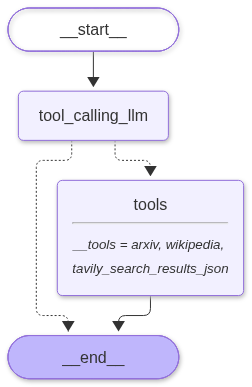

In [25]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
messages = graph.invoke({"messages" : "1706.03762"})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

1706.03762
================================== Ai Message ==================================
Tool Calls:
  arxiv (fc_8dc14b2b-6ade-46c9-b041-5e0d1d92cbe3)
 Call ID: fc_8dc14b2b-6ade-46c9-b041-5e0d1d92cbe3
  Args:
    query: 1706.03762
================================= Tool Message =================================
Name: arxiv

Published: 2023-08-02
Title: Attention Is All You Need
Authors: Ashish Vaswani, Noam Shazeer, Niki Parmar, Jakob Uszkoreit, Llion Jones, Aidan N. Gomez, Lukasz Kaiser, Illia Polosukhin
Summary: The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, base


In [27]:
messages = graph.invoke({"messages" : "Hi myself aarjv"})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Hi myself aarjv
================================== Ai Message ==================================

Hello, aarjv! 👋 Nice to meet you. How can I assist you today?


In [28]:
messages = graph.invoke({"messages" : "hii my name is aarjav and tell me recent quantum computing research papers"})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

hii my name is aarjav and tell me recent quantum computing research papers
================================== Ai Message ==================================
Tool Calls:
  arxiv (fc_f02ab662-c1b2-4a6c-aaea-aca732c8698b)
 Call ID: fc_f02ab662-c1b2-4a6c-aaea-aca732c8698b
  Args:
    query: quantum computing
================================= Tool Message =================================
Name: arxiv

Published: 2022-11-04
Title: Tierkreis: A Dataflow Framework for Hybrid Quantum-Classical Computing
Authors: Seyon Sivarajah, Lukas Heidemann, Alan Lawrence, Ross Duncan
Summary: We present Tierkreis, a higher-order dataflow graph program representation and runtime designed for compositional, quantum-classical hybrid algorithms. The design of the system is motivated by the remote nature of quantum computers, the need for hybrid algorithms to involve cloud and distributed computing, and the long-


In [31]:
messages = graph.invoke({"messages" : "what is the recent AI news and then tell me recent quantum computing research papers"})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

what is the recent AI news and then tell me recent quantum computing research papers
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (fc_bdc32eae-c337-494b-9f2b-907de529720d)
 Call ID: fc_bdc32eae-c337-494b-9f2b-907de529720d
  Args:
    query: latest AI news November 2026
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "AI news November 2026: 14 developments · Hello Growth", "url": "https://hellogrowth.ai/en/blog/ai-news-november-2026", "content": "> In short\n>\n>  AI news from late October and early November 2026 is mostly about limits: caps on free Copilot Chat, budgets in Claude, ChatGPT agents that switch on by default and models being retired.\n>  Fourteen developments matter for businesses, from new limits in Microsoft 365, dots in ChatGPT Enterpris